# Pandas for Real-World Data
## Types, Cleaning, Grouping, Joins and a Reproducible Analysis Pipeline

**Practical 4 — approximately 100 minutes**

NumPy gave us a clean numerical world:

$$X \in \mathbb{R}^{n \times d}.$$

Real datasets rarely arrive that way. They arrive with names, mixed types, timestamps, categories,
missing values, duplicate keys, inconsistent labels and invalid measurements.

The mental model for this session is therefore:

$$
\text{raw table}
\rightarrow
\text{inspect}
\rightarrow
\text{select}
\rightarrow
\text{type}
\rightarrow
\text{validate}
\rightarrow
\text{clean}
\rightarrow
\text{transform}
\rightarrow
\text{aggregate}
\rightarrow
\text{combine}
\rightarrow
\text{visualize}
$$

### Learning outcomes

After this session you should be able to:

1. inspect an unfamiliar table before changing it
2. select rows and columns precisely with `[]`, `.loc`, `.iloc` and boolean masks
3. distinguish a **storage dtype** from the **meaning** of a variable
4. parse numerical, string and datetime columns deliberately
5. treat missingness and invalid values as data-quality decisions rather than syntax problems
6. express transformations without row-by-row Python loops
7. summarize data with `groupby`, named aggregation and `pivot_table`
8. join tables while checking key cardinality
9. turn an exploratory notebook into a small reproducible cleaning pipeline

### Requirements

`pandas`, `numpy` and `matplotlib`. The notebook is compatible with pandas 2.2+, but targets the
current pandas 3.x user model: string columns have a dedicated string dtype and Copy-on-Write makes
`.loc[...] = ...` the clear update pattern.

### Session plan

| Time | Part | What you should discover |
|---|---|---|
| 0–10 min | 1. Load and inspect | a DataFrame is not “just a matrix” |
| 10–25 min | 2. Select precisely | column selection, `.loc`, `.iloc`, masks, sorting |
| 25–45 min | 3–4. Dtypes and cleaning | strings, numbers, dates, missingness, domain rules |
| 45–60 min | 5. Transform | vectorized columns, `map`, `where`, `assign`, categories |
| 60–75 min | 6. Aggregate | `value_counts`, `groupby`, named `agg`, `pivot_table` |
| 75–85 min | 7. Combine tables | `merge`, unmatched rows, key validation |
| 85–95 min | 8. Visual checks | plots as analysis and as quality control |
| 95–100 min | 9. Pipeline + Lab 1 bridge | reproducible function, clean matrix, exit challenge |

The core is Parts 1–7. The short sections on Copy-on-Write and categorical memory are there because
they explain current pandas behaviour, not because you need to memorize internals.

## 0. Environment

In [1]:
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:    ", sys.version.split()[0])
print("pandas:    ", pd.__version__)
print("NumPy:     ", np.__version__)
print("Platform:  ", platform.platform())

# pandas 3.x uses Copy-on-Write semantics unconditionally.
# On pandas 2.2 we enable them so this notebook teaches one consistent model.
if int(pd.__version__.split(".")[0]) < 3:
    pd.options.mode.copy_on_write = True
    print("Copy-on-Write enabled for pandas 2.x compatibility.")

Python:     3.13.13
pandas:     3.0.6
NumPy:      2.5.3
Platform:   Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39


### Course data

We use two small files throughout the entire session:

```text
data/transactions.csv
data/customers.csv
```

`transactions.csv` is intentionally imperfect. Do **not** assume that the file schema is correct merely
because `read_csv` succeeded.

If these files are distributed with the notebook, the next setup cell does nothing. If they are missing,
it creates the same deterministic teaching dataset so the notebook remains self-contained.

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
TX_PATH = DATA_DIR / "transactions.csv"
CUSTOMERS_PATH = DATA_DIR / "customers.csv"

if not (TX_PATH.exists() and CUSTOMERS_PATH.exists()):
    _rng = np.random.default_rng(2026)
    _n = 850

    _transaction_ids = np.arange(10001, 10001 + _n).astype(object)
    _customer_ids = _rng.integers(1, 121, size=_n).astype(object)

    _regions_base = np.array(["Kyiv", "Lviv", "Odesa", "Dnipro", "Kharkiv"])
    _regions = _rng.choice(
        _regions_base, size=_n, p=[0.34, 0.18, 0.16, 0.17, 0.15]
    ).astype(object)

    for _idx in _rng.choice(_n, 35, replace=False):
        _val = str(_regions[_idx])
        _regions[_idx] = _rng.choice(
            [_val.lower(), f" {_val}", f"{_val} ", _val.upper()]
        )

    _products = _rng.choice(
        ["Sensor", "Adapter", "Camera", "Controller", "Battery"],
        size=_n,
        p=[0.19, 0.26, 0.18, 0.17, 0.20],
    ).astype(object)

    _quantity = _rng.integers(1, 9, size=_n).astype(object)
    for _idx, _value in zip(
        _rng.choice(_n, 8, replace=False),
        [-3, -1, 0, -2, -5, 0, -1, -4],
    ):
        _quantity[_idx] = _value
    for _idx in _rng.choice(_n, 6, replace=False):
        _quantity[_idx] = "N/A"

    _base_prices = {
        "Sensor": 65.0,
        "Adapter": 18.0,
        "Camera": 140.0,
        "Controller": 95.0,
        "Battery": 42.0,
    }
    _unit_price = np.array(
        [
            f"{_base_prices[p] * _rng.lognormal(mean=0, sigma=0.10):.2f}"
            for p in _products
        ],
        dtype=object,
    )
    for _idx in _rng.choice(_n, 7, replace=False):
        _unit_price[_idx] = _rng.choice(["unknown", "", "?", "-12.50"])

    _discount = _rng.choice(
        [0.0, 0.05, 0.10, 0.15, 0.20],
        size=_n,
        p=[0.42, 0.19, 0.18, 0.13, 0.08],
    ).astype(float)
    for _idx in _rng.choice(_n, 5, replace=False):
        _discount[_idx] = _rng.choice([-0.1, 1.2, 2.0])

    _status = _rng.choice(
        ["completed", "pending", "cancelled"],
        size=_n,
        p=[0.74, 0.17, 0.09],
    ).astype(object)
    for _idx in _rng.choice(_n, 28, replace=False):
        _s = str(_status[_idx])
        _status[_idx] = _rng.choice(
            [_s.title(), f" {_s}", _s.upper(), "canceled" if _s == "cancelled" else _s]
        )

    _start = np.datetime64("2026-08-01T08:00")
    _minutes = _rng.integers(0, 45 * 24 * 60, size=_n)
    _times = _start + _minutes.astype("timedelta64[m]")
    _timestamp = np.empty(_n, dtype=object)

    for _i, _t in enumerate(_times):
        _py = pd.Timestamp(_t)
        _fmt = _rng.choice(
            ["%Y-%m-%d %H:%M", "%Y/%m/%d %H:%M", "%d.%m.%Y %H:%M"],
            p=[0.75, 0.15, 0.10],
        )
        _timestamp[_i] = _py.strftime(_fmt)

    for _idx in _rng.choice(_n, 6, replace=False):
        _timestamp[_idx] = _rng.choice(
            ["not-a-date", "2026-13-40", "", "tomorrow"]
        )

    for _arr, _count in [(_regions, 5), (_products, 4), (_status, 4)]:
        for _idx in _rng.choice(_n, _count, replace=False):
            _arr[_idx] = ""

    _transactions = pd.DataFrame(
        {
            "transaction_id": _transaction_ids,
            "timestamp": _timestamp,
            "customer_id": _customer_ids,
            "region": _regions,
            "product": _products,
            "quantity": _quantity,
            "unit_price": _unit_price,
            "discount": _discount,
            "status": _status,
        }
    )

    _dup_idx = _rng.choice(_n, 7, replace=False)
    _transactions = pd.concat(
        [_transactions, _transactions.iloc[_dup_idx]],
        ignore_index=True,
    )

    _unmatched_idx = _rng.choice(len(_transactions), 5, replace=False)
    _transactions.loc[_unmatched_idx, "customer_id"] = [9991, 9992, 9993, 9994, 9995]

    _ids = np.arange(1, 121)
    _customers = pd.DataFrame(
        {
            "customer_id": _ids,
            "segment": _rng.choice(
                ["student", "professional", "business"],
                size=len(_ids),
                p=[0.25, 0.55, 0.20],
            ),
            "signup_date": (
                pd.Timestamp("2024-01-01")
                + pd.to_timedelta(_rng.integers(0, 900, size=len(_ids)), unit="D")
            ).strftime("%Y-%m-%d"),
        }
    )

    _customers = pd.concat(
        [_customers, _customers.loc[_customers["customer_id"] == 17]],
        ignore_index=True,
    )

    _transactions.to_csv(TX_PATH, index=False)
    _customers.to_csv(CUSTOMERS_PATH, index=False)

print("transactions:", TX_PATH.resolve())
print("customers:   ", CUSTOMERS_PATH.resolve())

transactions: /home/roaffix/Workspace/LEC/ATP-2026/04-pandas-for-real-world/data/transactions.csv
customers:    /home/roaffix/Workspace/LEC/ATP-2026/04-pandas-for-real-world/data/customers.csv


---
## 1. Load first. Interpret second.

`read_csv` can infer a representation. It cannot infer your scientific or business meaning.

A column that *looks* numerical may contain an error token. A string may actually be a category.
A timestamp may be stored as text. A successful import therefore means only:

> pandas could construct a table from the file.

It does **not** mean the table is ready for analysis.

In [3]:
raw = pd.read_csv(TX_PATH)

raw.head()

,transaction_id,timestamp,customer_id,region,product,quantity,unit_price,discount,status
0,10001,2026/08/21 18:17,103,Kyiv,Battery,4.0,36.55,0.00,pending
1,10002,2026/09/05 19:58,22,Kyiv,Camera,8.0,142.71,0.10,completed
2,10003,2026-08-16 19:25,4,Kyiv,Adapter,1.0,17.65,0.00,pending
3,10004,2026-08-02 21:22,77,Kharkiv,Battery,4.0,46.08,0.00,completed
4,10005,2026-08-23 12:38,44,Kharkiv,Battery,3.0,47.21,0.05,cancelled


In [4]:
print("shape:", raw.shape)
print("\ncolumns:")
print(raw.columns.tolist())

print("\ndtypes:")
print(raw.dtypes)

shape: (857, 9)

columns:
['transaction_id', 'timestamp', 'customer_id', 'region', 'product', 'quantity', 'unit_price', 'discount', 'status']

dtypes:
transaction_id      int64
timestamp             str
customer_id         int64
region                str
product               str
quantity          float64
unit_price            str
discount          float64
status                str
dtype: object


In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  857 non-null    int64  
 1   timestamp       855 non-null    str    
 2   customer_id     857 non-null    int64  
 3   region          852 non-null    str    
 4   product         853 non-null    str    
 5   quantity        851 non-null    float64
 6   unit_price      856 non-null    str    
 7   discount        857 non-null    float64
 8   status          853 non-null    str    
dtypes: float64(2), int64(2), str(5)
memory usage: 60.4 KB


### First-pass audit

Before cleaning, answer these questions:

1. What does **one row** represent?
2. What should uniquely identify a row?
3. Which columns are numerical quantities, categories, identifiers or times?
4. Which values are impossible by definition?
5. Which missing values may change the interpretation of the analysis?

This is more important than remembering fifty DataFrame methods.

In [6]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,857.0,NaN,NaN,NaN,10425.866978,245.47923,10001.0,10214.0,10425.0,10638.0,10850.0
timestamp,855,845,2026-09-15 05:50,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,857.0,NaN,NaN,NaN,118.079347,757.684978,1.0,33.0,59.0,90.0,9995.0
region,852,21,Kyiv,247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,853,5,Adapter,238,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,851.0,NaN,NaN,NaN,4.361927,2.363578,-5.0,2.0,4.0,6.0,8.0
unit_price,856,794,?,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
discount,857.0,NaN,NaN,NaN,0.074037,0.142367,0.0,0.0,0.05,0.1,2.0
status,853,11,completed,598,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Notice that `describe(include="all")` is intentionally messy. Mixed dtypes produce different summaries.
That is useful at this stage: the table is telling us that its columns are not all the same kind of object.

---
## 2. Selecting data precisely

A DataFrame has **labels** as well as positions.

- `df["column"]` — one column
- `df[["a", "b"]]` — several columns
- `.loc[row_labels_or_mask, column_labels]` — label-aware selection
- `.iloc[row_positions, column_positions]` — positional selection

Most data cleaning is not “loop through the rows”. It is:

> describe the subset of the table to which an operation applies.

In [7]:
raw["region"].head()

0       Kyiv
1       Kyiv
2       Kyiv
3    Kharkiv
4    Kharkiv
Name: region, dtype: str

In [8]:
raw[["transaction_id", "region", "product", "quantity"]].head()

,transaction_id,region,product,quantity
0,10001,Kyiv,Battery,4.0
1,10002,Kyiv,Camera,8.0
2,10003,Kyiv,Adapter,1.0
3,10004,Kharkiv,Battery,4.0
4,10005,Kharkiv,Battery,3.0


In [9]:
# Label-based selection with a boolean condition.
expensive_or_large = raw.loc[
    (pd.to_numeric(raw["unit_price"], errors="coerce") > 100)
    | (pd.to_numeric(raw["quantity"], errors="coerce") >= 7),
    ["transaction_id", "product", "quantity", "unit_price"],
]

expensive_or_large.head(10)

,transaction_id,product,quantity,unit_price
1,10002,Camera,8.0,142.71
6,10007,Controller,3.0,110.47
8,10009,Camera,7.0,157.91
9,10010,Camera,2.0,137.86
10,10011,Camera,3.0,148.43
12,10013,Adapter,8.0,20.46
14,10015,Sensor,8.0,60.85
16,10017,Adapter,7.0,20.49
17,10018,Controller,5.0,110.05
18,10019,Camera,1.0,124.59


In [10]:
# Positional selection: useful for inspection, less useful for semantic cleaning rules.
raw.iloc[:5, :4]

,transaction_id,timestamp,customer_id,region
0,10001,2026/08/21 18:17,103,Kyiv
1,10002,2026/09/05 19:58,22,Kyiv
2,10003,2026-08-16 19:25,4,Kyiv
3,10004,2026-08-02 21:22,77,Kharkiv
4,10005,2026-08-23 12:38,44,Kharkiv


In [11]:
# Sort the table without changing the raw object.
raw.sort_values(
    ["region", "transaction_id"],
    na_position="last",
).head(10)

,transaction_id,timestamp,customer_id,region,product,quantity,unit_price,discount,status
197,10198,2026-08-31 11:38,28,Dnipro,Controller,5.0,106.79,0.00,completed
331,10332,2026/09/02 06:26,6,Dnipro,Adapter,1.0,15.07,0.00,completed
607,10608,2026-09-02 06:55,65,Kyiv,Adapter,5.0,15.27,0.00,completed
284,10285,2026-08-24 00:59,17,Lviv,Controller,4.0,89.60,0.10,completed
427,10428,tomorrow,50,Lviv,Camera,7.0,125.00,0.15,pending
315,10316,2026/09/02 15:50,51,DNIPRO,Camera,8.0,126.03,0.00,completed
391,10392,2026-08-26 02:12,60,DNIPRO,Adapter,2.0,18.08,0.15,pending
512,10513,14.09.2026 20:45,6,DNIPRO,Adapter,7.0,17.78,0.10,completed
11,10012,2026-09-13 03:30,95,Dnipro,Sensor,2.0,68.34,0.10,completed
15,10016,2026-09-15 05:50,22,Dnipro,Adapter,3.0,17.45,0.05,completed


### One update rule to remember

Use **one `.loc` assignment** when you intend to change a DataFrame:

```python
df.loc[condition, "column"] = value
```

Do not build habits around chained assignment such as:

```python
df["column"][condition] = value
```

In pandas 3.x, Copy-on-Write is the only behaviour: a subset behaves as a separate object from the
user's perspective, so modifying that subset does not modify its parent. `.loc` states the intended
mutation in one operation.

### Exercise A — selection

Without a Python loop:

1. select completed transactions from Kyiv
2. keep only `transaction_id`, `timestamp`, `product`, `quantity`, `unit_price`
3. sort them by `unit_price` descending

Do not clean the whole dataset yet. Use temporary expressions where conversion is needed.

In [12]:
# TODO

<details>
<summary><b>Solution</b></summary>

```python
region = raw["region"].astype("string").str.strip().str.casefold()
status = raw["status"].astype("string").str.strip().str.casefold()
price = pd.to_numeric(raw["unit_price"], errors="coerce")

answer = (
    raw.loc[
        region.eq("kyiv") & status.eq("completed"),
        ["transaction_id", "timestamp", "product", "quantity", "unit_price"],
    ]
    .assign(_sort_price=price)
    .sort_values("_sort_price", ascending=False)
    .drop(columns="_sort_price")
)

answer.head()
```

The temporary normalized `region`, `status` and numerical `price` are part of the selection logic.
They do not silently overwrite the raw input.
</details>

---
## 3. Dtypes: representation is not meaning

A DataFrame may contain NumPy dtypes **and** pandas extension dtypes.

For analysis, ask two different questions:

1. **How is this column stored?**
2. **What does this variable mean?**

An integer can be an identifier. A string can be a category. A numeric-looking string is not yet a
numerical variable. A timestamp stored as text has no temporal arithmetic until we parse it.

In [ ]:
# convert_dtypes gives us pandas' nullable dtypes where appropriate.
df = raw.convert_dtypes()

df.dtypes

transaction_id      Int64
timestamp          string
customer_id         Int64
region             string
product            string
quantity            Int64
unit_price         string
discount          Float64
status             string
dtype: object

On pandas 3.x, ordinary text read from CSV uses the dedicated `str` dtype by default. On pandas 2.x,
`convert_dtypes()` gives a nullable string dtype. Either way, do not write analysis logic that assumes
“text means NumPy `object`”.

For cross-version checks, use pandas' type predicates such as
`pd.api.types.is_string_dtype(...)`.

In [14]:
for column in ["region", "quantity", "discount"]:
    print(
        f"{column:10s}",
        "dtype =", df[column].dtype,
        "| string?", pd.api.types.is_string_dtype(df[column].dtype),
        "| numeric?", pd.api.types.is_numeric_dtype(df[column].dtype),
    )

region     dtype = string | string? True | numeric? False
quantity   dtype = Int64 | string? False | numeric? True
discount   dtype = Float64 | string? False | numeric? True


### Parse numbers explicitly

`errors="coerce"` turns values that cannot be parsed into missing values. That is not “fixing” them.
It is making the parsing failure explicit so we can decide what to do next.

In [15]:
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce").astype("Int64")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

print(df[["quantity", "unit_price"]].dtypes)
df[["quantity", "unit_price"]].head()

quantity        Int64
unit_price    Float64
dtype: object


,quantity,unit_price
0,4,36.55
1,8,142.71
2,1,17.65
3,4,46.08
4,3,47.21


### Parse dates explicitly

A timestamp gives us ordering, durations, calendar components and time-based grouping only after it
has been converted to a datetime dtype.

In [16]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    format="mixed",
    errors="coerce",
)

print(df["timestamp"].dtype)
print("unparseable timestamps:", df["timestamp"].isna().sum())
df["timestamp"].head()

datetime64[us]
unparseable timestamps: 6


0   2026-08-21 18:17:00
1   2026-09-05 19:58:00
2   2026-08-16 19:25:00
3   2026-08-02 21:22:00
4   2026-08-23 12:38:00
Name: timestamp, dtype: datetime64[us]

### Normalize text before treating it as a category

Whitespace and capitalization are representational differences unless the domain says otherwise.
Spelling differences are more dangerous: `"cancelled"` and `"canceled"` require an explicit semantic
decision.

In [17]:
for column in ["region", "product", "status"]:
    df[column] = df[column].str.strip().str.casefold()

df["status"] = df["status"].replace({"canceled": "cancelled"})

for column in ["region", "product", "status"]:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


region
region
kyiv       258
dnipro     171
lviv       147
odesa      140
kharkiv    136
<NA>         5
Name: count, dtype: Int64

product
product
adapter       238
sensor        170
battery       161
controller    151
camera        133
<NA>            4
Name: count, dtype: Int64

status
status
completed    611
pending      168
cancelled     74
<NA>           4
Name: count, dtype: Int64


Empty strings commonly become missing values when CSV is read, but the exact result depends on the
I/O options and source format. Always inspect the values you actually have.

---
## 4. Missing values and invalid values are different problems

A missing value means *we do not have a usable value*. An invalid value means *we have a value that
violates our domain rules*.

Examples for this dataset:

```text
quantity <= 0          invalid
unit_price <= 0        invalid
discount < 0 or > 0.8  invalid
bad timestamp          missing after parsing
unknown customer key   valid syntax, but referential-integrity problem
```

Cleaning begins by writing those rules down.

In [ ]:
missing = (
    df.isna()
    .sum()
    .rename("missing")
    .to_frame()
    .assign(percent=lambda x: 100 * x["missing"] / len(df))
)

missing.sort_values("missing", ascending=False)

,missing,percent
timestamp,6,0.700117
quantity,6,0.700117
unit_price,5,0.583431
region,5,0.583431
status,4,0.466744
product,4,0.466744
transaction_id,0,0.000000
customer_id,0,0.000000
discount,0,0.000000


In [19]:
quality_flags = pd.DataFrame(
    {
        "bad_quantity": df["quantity"].notna() & df["quantity"].le(0),
        "bad_price": df["unit_price"].notna() & df["unit_price"].le(0),
        "bad_discount": df["discount"].notna() & ~df["discount"].between(0, 0.8),
        "bad_timestamp": df["timestamp"].isna(),
        "duplicate_id": df["transaction_id"].duplicated(keep=False),
    }
)

quality_flags.sum().sort_values(ascending=False)

duplicate_id     14
bad_quantity      8
bad_timestamp     6
bad_discount      5
bad_price         2
dtype: Int64

A useful quality policy has four parts:

```text
rule → measurable test → threshold → action
```

For a lab, the action might simply be “mark as missing and document it”. In a production system it
might be “reject the record”, “quarantine the batch” or “alert the owner”.

In [20]:
# Convert impossible numerical values into explicit missingness.
df.loc[df["quantity"].le(0), "quantity"] = pd.NA
df.loc[df["unit_price"].le(0), "unit_price"] = np.nan
df.loc[~df["discount"].between(0, 0.8), "discount"] = np.nan

# Duplicates are a separate decision: here transaction_id is intended to identify one transaction.
before = len(df)
df = df.drop_duplicates(subset="transaction_id", keep="first")
print("rows removed as duplicate transaction IDs:", before - len(df))

rows removed as duplicate transaction IDs: 7


### Do not automatically `fillna(0)`

For `discount`, zero may be a meaningful default if the source system defines missing as “no discount”.
For `unit_price`, zero would create fake free products. For `timestamp`, there is no sensible numeric
zero at all.

The correct replacement depends on the **data-generating process**, not on pandas syntax.

In [21]:
# In this teaching dataset, a missing discount means no discount was recorded.
# We choose 0 only because we explicitly adopt that domain rule.
df["discount"] = df["discount"].fillna(0.0)

df.isna().sum().sort_values(ascending=False)

quantity          14
unit_price         7
timestamp          6
region             5
status             4
product            4
transaction_id     0
customer_id        0
discount           0
dtype: int64

### Exercise B — audit before repair

Build one table with the number of:

- missing values
- unique non-missing values
- percentage missing

for every column.

Sort it by percentage missing, descending.

In [22]:
# TODO

<details>
<summary><b>Solution</b></summary>

```python
audit = pd.DataFrame(
    {
        "missing": df.isna().sum(),
        "unique_non_missing": df.nunique(dropna=True),
    }
)

audit["percent_missing"] = 100 * audit["missing"] / len(df)
audit.sort_values("percent_missing", ascending=False)
```
</details>

---
## 5. Transformations: operate on columns, not Python rows

Once the schema is usable, create variables that represent the quantities you actually want to analyse.

For a completed transaction,

$$
	ext{revenue}
=
	ext{quantity}
	imes
	ext{unit price}
	imes
(1-	ext{discount}).
$$

In [23]:
df["gross_value"] = df["quantity"] * df["unit_price"]
df["revenue"] = df["gross_value"] * (1.0 - df["discount"])

df[["quantity", "unit_price", "discount", "gross_value", "revenue"]].head()

,quantity,unit_price,discount,gross_value,revenue
0,4,36.55,0.0,146.2,146.2
1,8,142.71,0.1,1141.68,1027.512
2,1,17.65,0.0,17.65,17.65
3,4,46.08,0.0,184.32,184.32
4,3,47.21,0.05,141.63,134.5485


That expression is preferable to:

```python
df.apply(lambda row: ..., axis=1)
```

when the operation is naturally column-wise. It is shorter, states the mathematics more clearly, and
lets pandas/NumPy execute bulk operations instead of repeatedly calling Python for every row.

In [24]:
# `map` is useful for a finite semantic mapping.
status_weight = {
    "completed": 1.0,
    "pending": 0.5,
    "cancelled": 0.0,
}

df["status_weight"] = df["status"].map(status_weight)

# `where` keeps the original value where a condition is true and substitutes otherwise.
df["recognized_revenue"] = df["revenue"].where(
    df["status"].eq("completed"),
    0.0,
)

df[["status", "revenue", "recognized_revenue", "status_weight"]].head(10)

,status,revenue,recognized_revenue,status_weight
0,pending,146.2,0.0,0.5
1,completed,1027.512,1027.512,1.0
2,pending,17.65,0.0,0.5
3,completed,184.32,184.32,1.0
4,cancelled,134.5485,0.0,0.0
5,pending,101.802,0.0,0.5
6,completed,314.8395,314.8395,1.0
7,pending,<NA>,0.0,0.5
8,completed,1105.37,1105.37,1.0
9,completed,248.148,248.148,1.0


In [25]:
# Datetime accessors turn timestamps into useful analysis variables.
df = df.assign(
    date=lambda x: x["timestamp"].dt.date,
    weekday=lambda x: x["timestamp"].dt.day_name(),
    hour=lambda x: x["timestamp"].dt.hour,
)

df[["timestamp", "date", "weekday", "hour"]].head()

,timestamp,date,weekday,hour
0,2026-08-21 18:17:00,2026-08-21,Friday,18.0
1,2026-09-05 19:58:00,2026-09-05,Saturday,19.0
2,2026-08-16 19:25:00,2026-08-16,Sunday,19.0
3,2026-08-02 21:22:00,2026-08-02,Sunday,21.0
4,2026-08-23 12:38:00,2026-08-23,Sunday,12.0


### Categories

Low-cardinality labels such as status or region can be represented as categorical values. This makes
the intended semantics explicit and can reduce memory use when labels repeat many times.

In [26]:
status_as_string = df["status"]
status_as_category = df["status"].astype("category")

print("string/category values are equal:",
      status_as_string.astype("string").equals(status_as_category.astype("string")))

print("memory as string/category source:",
      status_as_string.memory_usage(deep=True), "bytes")
print("memory as category:              ",
      status_as_category.memory_usage(deep=True), "bytes")
print("categories:", status_as_category.cat.categories.tolist())

df["status"] = status_as_category

string/category values are equal: True
memory as string/category source: 49088 bytes
memory as category:               1154 bytes
categories: ['cancelled', 'completed', 'pending']


`category` is not a universal “optimization switch”. It is appropriate when the set of labels is
meaningful and relatively small. A high-cardinality free-text field is a different object.

---
## 6. Aggregation: from rows to evidence

`groupby` answers questions of the form:

> split the rows into groups → compute a statistic inside each group → combine the results.

This is the tabular analogue of a reduction.

In [27]:
df["region"].value_counts(dropna=False)

region
kyiv       258
dnipro     171
lviv       145
odesa      137
kharkiv    134
<NA>         5
Name: count, dtype: Int64

In [28]:
completed = df.loc[df["status"].eq("completed")].copy()

region_summary = (
    completed
    .groupby("region", dropna=False)
    .agg(
        transactions=("transaction_id", "size"),
        total_revenue=("revenue", "sum"),
        mean_revenue=("revenue", "mean"),
        median_revenue=("revenue", "median"),
        customers=("customer_id", "nunique"),
    )
    .sort_values("total_revenue", ascending=False)
)

region_summary

,transactions,total_revenue,mean_revenue,median_revenue,customers
region,,,,,
kyiv,192,48352.613,255.833931,172.38,102
lviv,114,34791.4385,313.436383,216.699,74
odesa,97,29709.58,312.732421,234.24,64
kharkiv,90,27096.694,304.457236,226.984,67
dnipro,109,27064.3175,255.32375,148.158,72
<NA>,3,648.15,324.075,324.075,3


Named aggregation is worth learning because the output schema is explicit:

```python
new_column=("source_column", "aggregation")
```

Compare that with receiving a MultiIndex of unnamed statistics and fixing it later.

In [29]:
product_region = pd.pivot_table(
    completed,
    index="region",
    columns="product",
    values="revenue",
    aggfunc="sum",
    fill_value=0,
)

product_region.round(2)

product,adapter,battery,camera,controller,sensor
region,,,,,
dnipro,2982.02,3074.46,9800.6,7274.28,3773.44
kharkiv,1406.5,3435.7,9559.1,6495.88,6199.52
kyiv,3831.58,6433.22,13737.67,13606.42,10743.72
lviv,2172.32,4452.76,13083.2,8532.41,6550.74
odesa,1637.2,2335.62,15443.85,5304.74,4988.16


### Exercise C — a question, not an API

Find, for every product:

1. the number of completed transactions
2. total revenue
3. median transaction revenue
4. the region with the highest total revenue for that product

The first three should be one `groupby`. Solve the fourth however you find clearest.

In [30]:
# TODO

<details>
<summary><b>One solution</b></summary>

```python
product_summary = (
    completed.groupby("product")
    .agg(
        transactions=("transaction_id", "size"),
        total_revenue=("revenue", "sum"),
        median_revenue=("revenue", "median"),
    )
)

by_region = (
    completed.groupby(["product", "region"], as_index=False)
    .agg(total_revenue=("revenue", "sum"))
)

best_region = (
    by_region.sort_values("total_revenue", ascending=False)
    .drop_duplicates("product")
    .set_index("product")[["region", "total_revenue"]]
    .rename(columns={"total_revenue": "best_region_revenue"})
)

product_summary.join(best_region)
```

There are several valid solutions. The important part is that the grouping level matches the question.
</details>

---
## 7. Combining tables: a join is a modeling assumption

A transaction contains `customer_id`, but customer attributes live in another table.

The join key is not syntax decoration. Its cardinality determines what the merge means:

```text
one-to-one
one-to-many
many-to-one
many-to-many
```

Accidentally performing a many-to-many merge can multiply rows and silently change every aggregate
that follows.

In [31]:
customers_raw = pd.read_csv(CUSTOMERS_PATH).convert_dtypes()

print("shape:", customers_raw.shape)
print("duplicate customer IDs:", customers_raw["customer_id"].duplicated(keep=False).sum())
customers_raw.loc[
    customers_raw["customer_id"].duplicated(keep=False)
].sort_values("customer_id")

shape: (121, 3)
duplicate customer IDs: 2


,customer_id,segment,signup_date
16,17,business,2025-11-02
120,17,business,2025-11-02


In [32]:
# Ask pandas to verify the relationship we believe should hold.
try:
    df.merge(
        customers_raw,
        on="customer_id",
        how="left",
        validate="many_to_one",
    )
except pd.errors.MergeError as exc:
    print(type(exc).__name__ + ":", exc)

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
  customer_id
          17 ...


That exception is valuable. It prevents a data-model error from becoming a plausible-looking result.
We must decide what the duplicate customer key means before merging.

In [33]:
# In this teaching file the duplicate customer row is exact, so deduplicating is justified.
customers = customers_raw.drop_duplicates(subset="customer_id")

enriched = df.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

enriched["_merge"].value_counts()

_merge
both          845
left_only       5
right_only      0
Name: count, dtype: int64

In [34]:
# Which transactions did not find a customer record?
enriched.loc[
    enriched["_merge"].ne("both"),
    ["transaction_id", "customer_id", "region", "_merge"],
]

,transaction_id,customer_id,region,_merge
171,10172,9994,dnipro,left_only
183,10184,9992,odesa,left_only
250,10251,9993,kyiv,left_only
368,10369,9991,kyiv,left_only
420,10421,9995,kharkiv,left_only


An unmatched key is not automatically “bad data”. It could mean:

- a late-arriving dimension table
- a deleted customer
- a different identifier system
- a genuinely corrupted key

The merge tells you **where** the mismatch is. Domain knowledge tells you what it means.

### Exercise D — join integrity

Before looking at customer segments, write checks for these assumptions:

1. `customers.customer_id` is unique
2. every non-missing `customer_id` in the analytical transaction table exists in `customers`
3. the merge must not increase the number of transaction rows

Make the checks executable rather than writing them as comments.

In [35]:
# TODO

<details>
<summary><b>Solution</b></summary>

```python
assert customers["customer_id"].is_unique

known_ids = set(customers["customer_id"])
unknown_ids = set(df["customer_id"].dropna()) - known_ids
print("unknown customer IDs:", sorted(unknown_ids))

merged_check = df.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
)

assert len(merged_check) == len(df)
```

Whether the second check should be an `assert` depends on the actual data contract. In this teaching
dataset we deliberately keep several unmatched IDs so that the issue remains visible.
</details>

---
## 8. Visualization is also a quality check

A plot is not the final decoration of an analysis. It can expose:

- heavy tails
- impossible values
- skew
- group imbalance
- temporal gaps
- suspicious spikes

Use plots after you understand what the axes mean.

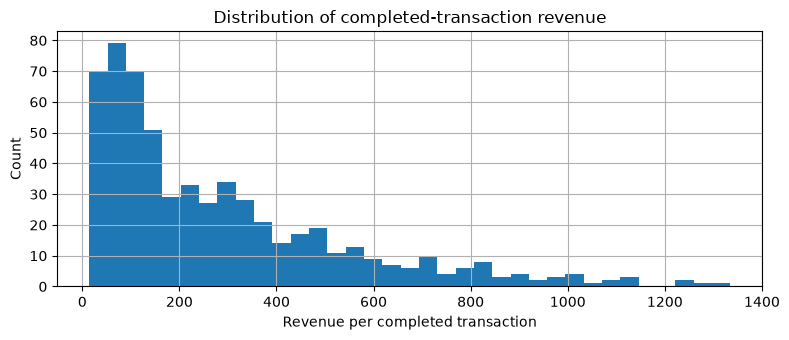

In [36]:
fig, ax = plt.subplots(figsize=(8, 3.5))

completed["revenue"].dropna().hist(
    bins=35,
    ax=ax,
)

ax.set_xlabel("Revenue per completed transaction")
ax.set_ylabel("Count")
ax.set_title("Distribution of completed-transaction revenue")
fig.tight_layout()
plt.show()

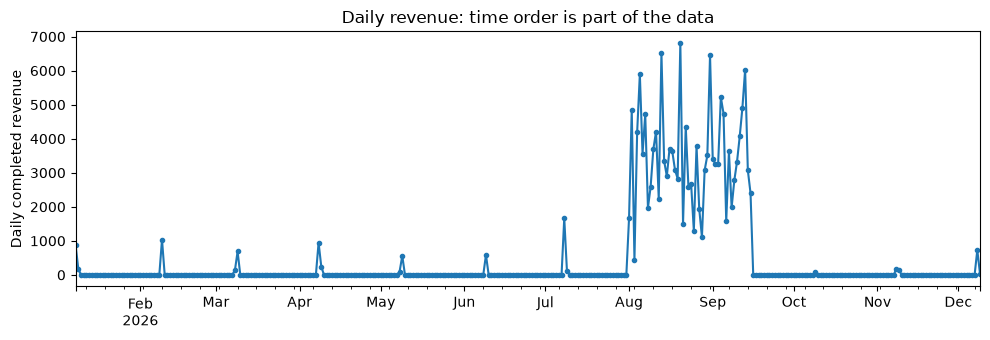

In [37]:
daily = (
    completed
    .dropna(subset=["timestamp", "revenue"])
    .set_index("timestamp")
    .resample("D")["revenue"]
    .sum()
)

fig, ax = plt.subplots(figsize=(10, 3.5))
daily.plot(ax=ax, marker="o", ms=3)
ax.set_ylabel("Daily completed revenue")
ax.set_xlabel("")
ax.set_title("Daily revenue: time order is part of the data")
fig.tight_layout()
plt.show()

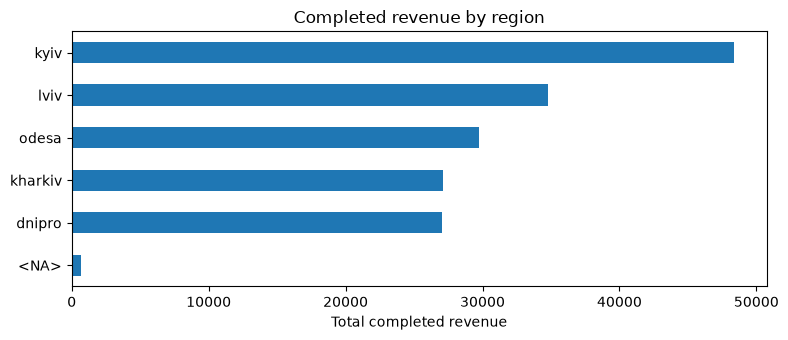

In [38]:
fig, ax = plt.subplots(figsize=(8, 3.5))

region_summary["total_revenue"].sort_values().plot.barh(ax=ax)

ax.set_xlabel("Total completed revenue")
ax.set_ylabel("")
ax.set_title("Completed revenue by region")
fig.tight_layout()
plt.show()

Do not read causal stories from these plots. They describe this dataset. Explaining *why* one region
has more revenue would require information about exposure, customer mix, selection and the
data-generating process.

---
## 9. From exploratory cells to a reproducible cleaning pipeline

An analysis notebook is allowed to be exploratory. The transformations you trust should eventually
become explicit functions.

A useful structure is:

```text
raw input
   ↓
clean_transactions(...)
   ↓
validated analytical table
   ↓
aggregation / model / figure
```

The function below intentionally contains **decisions**, not merely method calls.

In [39]:
def clean_transactions(raw: pd.DataFrame) -> pd.DataFrame:
    out = raw.convert_dtypes()

    # Parse representation.
    out["quantity"] = pd.to_numeric(out["quantity"], errors="coerce").astype("Int64")
    out["unit_price"] = pd.to_numeric(out["unit_price"], errors="coerce")
    out["timestamp"] = pd.to_datetime(
        out["timestamp"],
        format="mixed",
        errors="coerce",
    )

    # Canonicalize text.
    for column in ["region", "product", "status"]:
        out[column] = out[column].str.strip().str.casefold()

    out["status"] = out["status"].replace({"canceled": "cancelled"})

    # Domain rules.
    out.loc[out["quantity"].le(0), "quantity"] = pd.NA
    out.loc[out["unit_price"].le(0), "unit_price"] = np.nan
    out.loc[~out["discount"].between(0, 0.8), "discount"] = np.nan

    # Domain decision for this dataset only.
    out["discount"] = out["discount"].fillna(0.0)

    # Transaction ID is intended to be unique.
    out = out.drop_duplicates(subset="transaction_id", keep="first")

    # Derived quantities.
    out["gross_value"] = out["quantity"] * out["unit_price"]
    out["revenue"] = out["gross_value"] * (1.0 - out["discount"])

    return out

In [40]:
clean = clean_transactions(pd.read_csv(TX_PATH))

print("rows:", len(clean))
print("transaction IDs unique:", clean["transaction_id"].is_unique)
print("negative/zero quantities:", clean["quantity"].le(0).fillna(False).sum())
print("negative/zero prices:    ", clean["unit_price"].le(0).fillna(False).sum())

clean.head()

rows: 850
transaction IDs unique: True
negative/zero quantities: 0
negative/zero prices:     0


,transaction_id,timestamp,customer_id,region,product,quantity,unit_price,discount,status,gross_value,revenue
0,10001,2026-08-21 18:17:00,103,kyiv,battery,4,36.55,0.0,pending,146.2,146.2
1,10002,2026-09-05 19:58:00,22,kyiv,camera,8,142.71,0.1,completed,1141.68,1027.512
2,10003,2026-08-16 19:25:00,4,kyiv,adapter,1,17.65,0.0,pending,17.65,17.65
3,10004,2026-08-02 21:22:00,77,kharkiv,battery,4,46.08,0.0,completed,184.32,184.32
4,10005,2026-08-23 12:38:00,44,kharkiv,battery,3,47.21,0.05,cancelled,141.63,134.5485


### A small contract

Tests can make the assumptions visible:

```python
assert clean["transaction_id"].is_unique
assert not clean["quantity"].dropna().le(0).any()
assert not clean["unit_price"].dropna().le(0).any()
assert clean["discount"].between(0, 0.8).all()
```

Do not assert away legitimate missing values. A test should encode a real invariant.

In [41]:
assert clean["transaction_id"].is_unique
assert not clean["quantity"].dropna().le(0).any()
assert not clean["unit_price"].dropna().le(0).any()
assert clean["discount"].between(0, 0.8).all()

print("data-quality invariants passed")

data-quality invariants passed


---
## 10. The bridge back to NumPy — and forward to the rest of the course

Pandas is excellent for labeled, heterogeneous tables. Many numerical algorithms expect a homogeneous
matrix.

Once the data are clean, selecting a numerical feature matrix should be an explicit boundary:

In [42]:
feature_columns = ["quantity", "unit_price", "discount"]

model_rows = clean.dropna(subset=feature_columns)
X = model_rows[feature_columns].to_numpy(dtype=np.float64)

print("X.shape:", X.shape)
print("X.dtype:", X.dtype)
print(X[:5])

X.shape: (830, 3)
X.dtype: float64
[[4.0000e+00 3.6550e+01 0.0000e+00]
 [8.0000e+00 1.4271e+02 1.0000e-01]
 [1.0000e+00 1.7650e+01 0.0000e+00]
 [4.0000e+00 4.6080e+01 0.0000e+00]
 [3.0000e+00 4.7210e+01 5.0000e-02]]


This is the hand-off point to later topics:

```text
Pandas table
   ↓
clean / type / validate
   ↓
feature matrix X
   ↓
NumPy / SciPy / scikit-learn
   ↓
PCA / LDA / clustering / embeddings / modelling
```

The important lesson is not “Pandas replaces NumPy”. They solve different parts of the same pipeline.

---
## Exit challenge — prepare for Lab 1

Starting again from `pd.read_csv(TX_PATH)`, produce a table with **one row per region** containing:

- number of unique completed transactions
- number of unique customers
- total completed revenue
- median completed revenue
- percentage of completed transactions with a missing usable `unit_price`

Then make one plot that communicates one meaningful comparison.

### Constraints

1. Do not modify the original CSV.
2. Do not loop over rows.
3. State every cleaning rule you use.
4. Your result must be reproducible from a fresh kernel.
5. Be prepared to explain why each missing-value decision is reasonable.

This is almost the workflow of **Lab 1**, but the laboratory will use a different dataset and you will
have to make the decisions yourself.

In [43]:
# Your solution starts here.

---
## Summary

The progression of this session, in one column:

```text
What does one row mean?
        ↓
What did pandas infer?
        ↓
Which subset do I need?
        ↓
Which dtypes match the semantics?
        ↓
Which values are missing, and which are invalid?
        ↓
Which cleaning rules am I assuming?
        ↓
Which derived variables answer the question?
        ↓
At what level should I aggregate?
        ↓
Can I trust the join keys?
        ↓
What does a plot reveal?
        ↓
Can I rerun the whole pipeline from raw input?
```

The closing rule:

> **A clean DataFrame is not one with no `NaN`s. It is one whose representation and assumptions are
> explicit enough that the next analysis step has a defensible meaning.**

### Further reading

- pandas user guide: [10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html)
- [Indexing and selecting data](https://pandas.pydata.org/docs/user_guide/indexing.html)
- [Working with missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html)
- [Working with text data](https://pandas.pydata.org/docs/user_guide/text.html)
- [Categorical data](https://pandas.pydata.org/docs/user_guide/categorical.html)
- [GroupBy](https://pandas.pydata.org/docs/user_guide/groupby.html)
- [Merge, join and concatenate](https://pandas.pydata.org/docs/user_guide/merging.html)
- [Copy-on-Write](https://pandas.pydata.org/docs/user_guide/copy_on_write.html)
- [Chart visualization](https://pandas.pydata.org/docs/user_guide/visualization.html)